# Used Car Price Prediction

This notebook starts with a linear regression on used car prices, then revisits two choices from the original exercise. Does the car's model name improve predictions? Does training on log prices help?

The baseline follows the 365 Data Science regression exercise. The final comparison uses the same held-out cars for all three fits.

**Run this notebook** by placing the course CSV, `1.04Reallifeexample.csv`, next to the notebook and running the cells in order. Use Python 3.11 or later with NumPy, pandas, Matplotlib, seaborn, SciPy, and scikit-learn 1.8 or later.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import seaborn as sns
sns.set()

## 1. Load and inspect the data

In [ ]:
raw_data = pd.read_csv('1.04Reallifeexample.csv')
print(raw_data.shape)
display(raw_data.head())

(4345, 9)


,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year,Model
0,BMW,4200.0,sedan,277,2.0,Petrol,yes,1991,320
1,Mercedes-Benz,7900.0,van,427,2.9,Diesel,yes,1999,Sprinter 212
2,Mercedes-Benz,13300.0,sedan,358,5.0,Gas,yes,2003,S 500
3,Audi,23000.0,crossover,240,4.2,Petrol,yes,2007,Q7
4,Toyota,18300.0,crossover,120,2.0,Petrol,yes,2011,Rav 4


In [ ]:
raw_data.describe(include='all')

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year,Model
count,4345,4173.000000,4345,4345.000000,4195.000000,4345,4345,4345.000000,4345
unique,7,NaN,6,NaN,NaN,4,2,NaN,312
top,Volkswagen,NaN,sedan,NaN,NaN,Diesel,yes,NaN,E-Class
freq,936,NaN,1649,NaN,NaN,2019,3947,NaN,199
mean,NaN,19418.746935,NaN,161.237284,2.790734,NaN,NaN,2006.550058,NaN
std,NaN,25584.242620,NaN,105.705797,5.066437,NaN,NaN,6.719097,NaN
min,NaN,600.000000,NaN,0.000000,0.600000,NaN,NaN,1969.000000,NaN
25%,NaN,6999.000000,NaN,86.000000,1.800000,NaN,NaN,2003.000000,NaN
50%,NaN,11500.000000,NaN,155.000000,2.200000,NaN,NaN,2008.000000,NaN
75%,NaN,21700.000000,NaN,230.000000,3.000000,NaN,NaN,2012.000000,NaN


## 2. Clean the data

The original baseline drops `Model`. I keep that choice here so the last section can measure what changes when it is added back.

In [ ]:
data = raw_data.drop(['Model'],axis=1)
print(data.shape)

(4345, 8)


In [ ]:
data.isnull().sum()

Brand             0
Price           172
Body              0
Mileage           0
EngineV         150
Engine Type       0
Registration      0
Year              0
dtype: int64

In [ ]:
data_no_mv = data.dropna(axis=0)


### Filter outliers

I trim the upper tail of price and mileage, remove engine volumes of 6.5 and above, and trim the oldest model years. These filters reduce 4,025 complete records to 3,867.

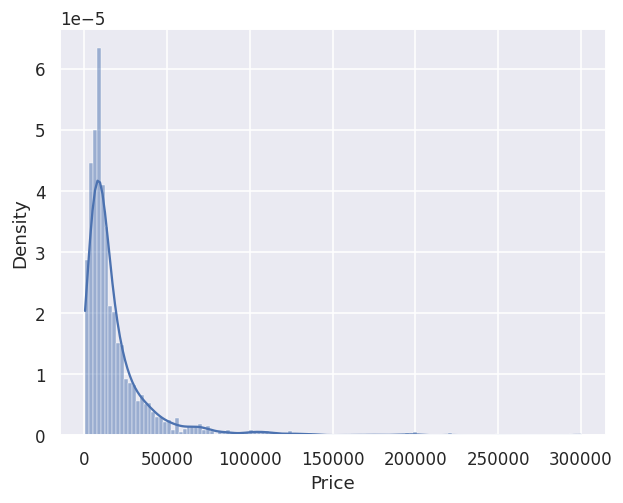

In [ ]:
sns.histplot(data_no_mv['Price'], stat='density', kde=True)

In [ ]:
q = data_no_mv['Price'].quantile(0.99)
data_1= data_no_mv[data_no_mv['Price']<q]
data_1.describe(include='all')

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year
count,3984,3984.000000,3984,3984.000000,3984.000000,3984,3984,3984.000000
unique,7,NaN,6,NaN,NaN,4,2,NaN
top,Volkswagen,NaN,sedan,NaN,NaN,Diesel,yes,NaN
freq,880,NaN,1528,NaN,NaN,1853,3613,NaN
mean,NaN,17837.117460,NaN,165.116466,2.743770,NaN,NaN,2006.292922
std,NaN,18976.268315,NaN,102.766126,4.956057,NaN,NaN,6.672745
min,NaN,600.000000,NaN,0.000000,0.600000,NaN,NaN,1969.000000
25%,NaN,6980.000000,NaN,93.000000,1.800000,NaN,NaN,2002.750000
50%,NaN,11400.000000,NaN,160.000000,2.200000,NaN,NaN,2007.000000
75%,NaN,21000.000000,NaN,230.000000,3.000000,NaN,NaN,2011.000000


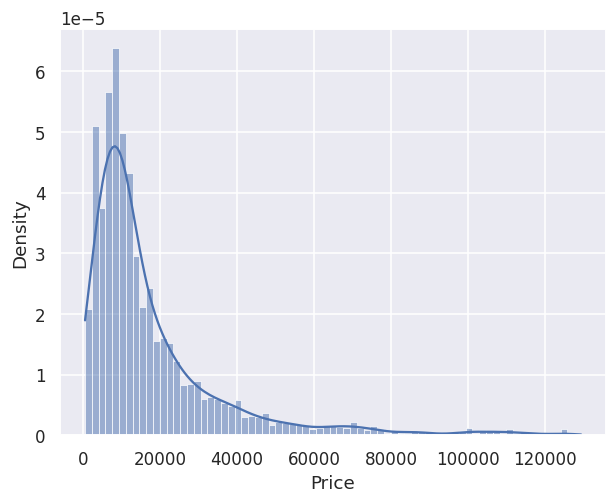

In [ ]:
sns.histplot(data_1['Price'], stat='density', kde=True)

In [ ]:
q = data_1['Mileage'].quantile(0.99)
data_2= data_1[data_1['Mileage']<q]

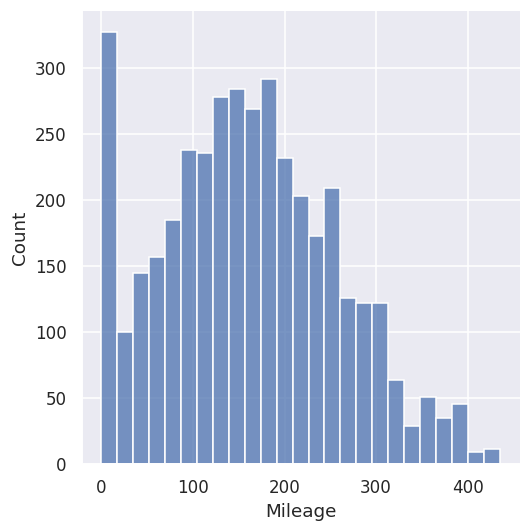

In [ ]:
sns.displot(data_2['Mileage'])

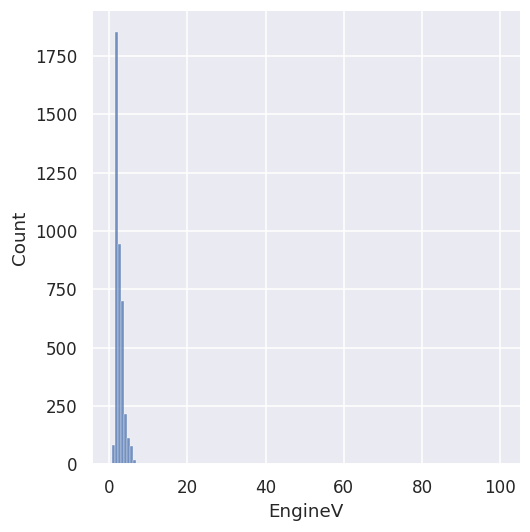

In [ ]:
sns.displot(data_no_mv['EngineV'])


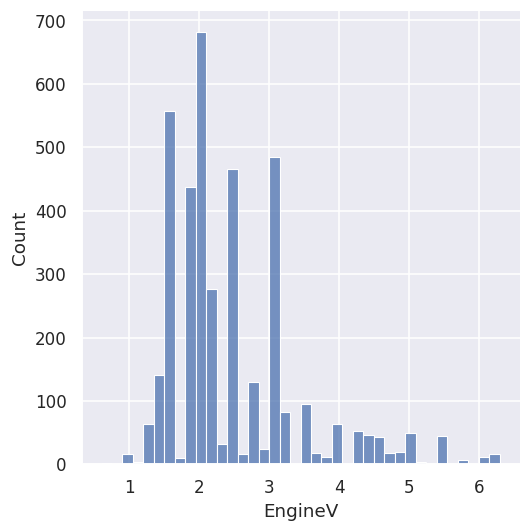

In [ ]:
data_3 = data_2[data_2['EngineV']<6.5]
sns.displot(data_3['EngineV'])

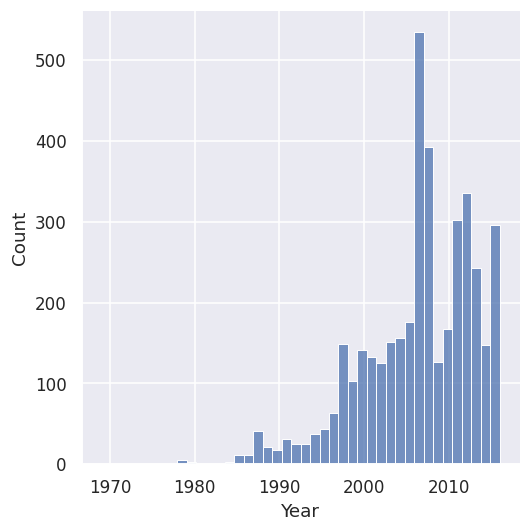

In [ ]:
sns.displot(data_no_mv['Year'])

In [ ]:
q = data_3['Year'].quantile(0.01)
data_4= data_3[data_3['Year']>q]

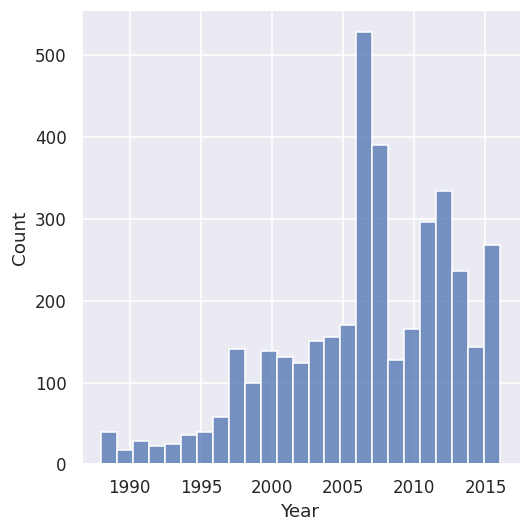

In [ ]:
sns.displot(data_4['Year'])

In [ ]:
data_cleaned = data_4.reset_index(drop=True)

In [ ]:
data_cleaned.describe(include='all')

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year
count,3867,3867.000000,3867,3867.000000,3867.000000,3867,3867,3867.000000
unique,7,NaN,6,NaN,NaN,4,2,NaN
top,Volkswagen,NaN,sedan,NaN,NaN,Diesel,yes,NaN
freq,848,NaN,1467,NaN,NaN,1807,3505,NaN
mean,NaN,18194.455679,NaN,160.542539,2.450440,NaN,NaN,2006.709853
std,NaN,19085.855165,NaN,95.633291,0.949366,NaN,NaN,6.103870
min,NaN,800.000000,NaN,0.000000,0.600000,NaN,NaN,1988.000000
25%,NaN,7200.000000,NaN,91.000000,1.800000,NaN,NaN,2003.000000
50%,NaN,11700.000000,NaN,157.000000,2.200000,NaN,NaN,2008.000000
75%,NaN,21700.000000,NaN,225.000000,3.000000,NaN,NaN,2012.000000


In [ ]:
print('No missing values:', data_no_mv.shape)
print('After price filter:', data_1.shape)
print('After mileage filter:', data_2.shape)
print('After engine filter:', data_3.shape)
print('After year filter:', data_4.shape)

No missing values: (4025, 8)
After price filter: (3984, 8)
After mileage filter: (3944, 8)
After engine filter: (3921, 8)
After year filter: (3867, 8)


## 3. Explore price and log price

The price distribution has a long right tail. I look at the relationships with year, engine volume, and mileage before and after taking the natural log of price.

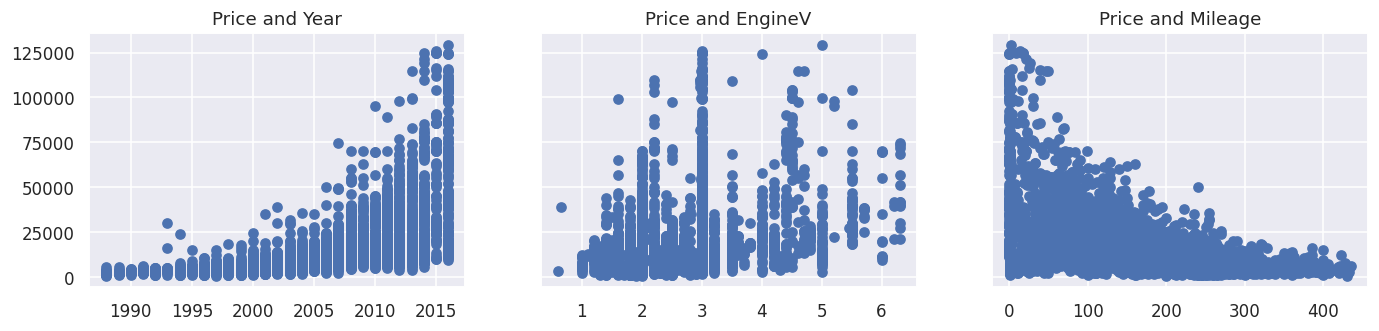

In [ ]:
f, (ax1, ax2, ax3)=plt.subplots(1, 3, sharey = True, figsize =(15,3))
ax1.scatter(data_cleaned['Year'],data_cleaned['Price'])
ax1.set_title('Price and Year')
ax2.scatter(data_cleaned['EngineV'],data_cleaned['Price'])
ax2.set_title('Price and EngineV')
ax3.scatter(data_cleaned['Mileage'],data_cleaned['Price'])
ax3.set_title('Price and Mileage')

plt.show()

In [ ]:
log_price = np.log(data_cleaned['Price'])
data_cleaned['log_price']=log_price

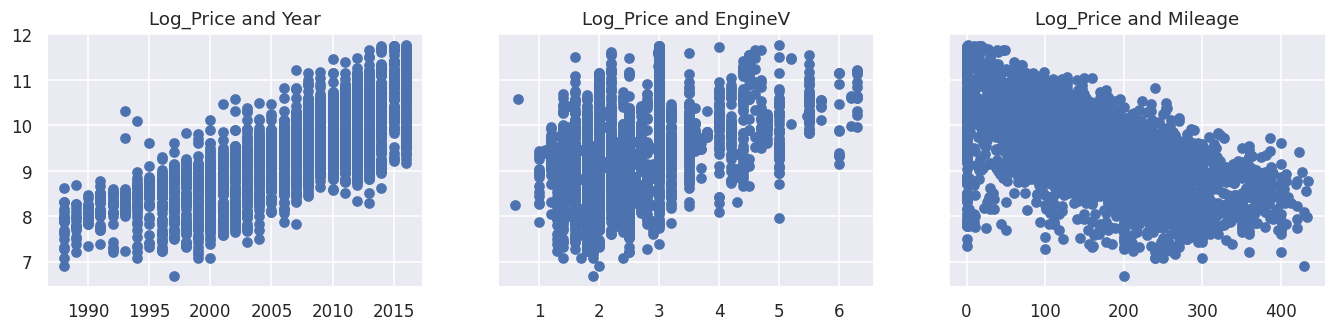

In [ ]:
f, (ax1, ax2, ax3)=plt.subplots(1, 3, sharey = True, figsize =(15,3) )
ax1.scatter(data_cleaned['Year'],data_cleaned['log_price'])
ax1.set_title('Log_Price and Year')
ax2.scatter(data_cleaned['EngineV'],data_cleaned['log_price'])
ax2.set_title('Log_Price and EngineV')
ax3.scatter(data_cleaned['Mileage'],data_cleaned['log_price'])
ax3.set_title('Log_Price and Mileage' )

plt.show()

In [ ]:
data_cleaned = data_cleaned.drop(['Price'],axis=1)

### Check multicollinearity

I calculate variance inflation factors for mileage, year, and engine volume. I leave `Year` out of the baseline and all three comparison fits. That keeps the comparison focused on the model name and the target transformation.

In [ ]:
variables = data_cleaned[['Mileage', 'Year', 'EngineV']]
vif = pd.DataFrame({'features': variables.columns})
vif_values = []

for feature in variables:
    other_features = variables.drop(columns=feature)
    auxiliary_regression = LinearRegression().fit(other_features, variables[feature])
    r_squared = auxiliary_regression.score(other_features, variables[feature])
    vif_values.append(1 / (1 - r_squared))

vif['VIF'] = vif_values
vif

,features,VIF
0,Mileage,2.048411
1,Year,2.049176
2,EngineV,1.000562


In [ ]:
data_no_multicollinearity = data_cleaned.drop(['Year'],axis=1)

### Encode categorical features

In [ ]:
data_with_dummies = pd.get_dummies(data_no_multicollinearity,drop_first=True)

In [ ]:
cols = ['log_price', 'Mileage', 'EngineV', 'Brand_BMW',
       'Brand_Mercedes-Benz', 'Brand_Mitsubishi', 'Brand_Renault',
       'Brand_Toyota', 'Brand_Volkswagen', 'Body_hatch', 'Body_other',
       'Body_sedan', 'Body_vagon', 'Body_van', 'Engine Type_Gas',
       'Engine Type_Other', 'Engine Type_Petrol', 'Registration_yes']

In [ ]:
data_preprocessed = data_with_dummies[cols]
data_preprocessed.head()

,log_price,Mileage,EngineV,Brand_BMW,Brand_Mercedes-Benz,Brand_Mitsubishi,Brand_Renault,Brand_Toyota,Brand_Volkswagen,Body_hatch,Body_other,Body_sedan,Body_vagon,Body_van,Engine Type_Gas,Engine Type_Other,Engine Type_Petrol,Registration_yes
0,8.342840,277,2.0,True,False,False,False,False,False,False,False,True,False,False,False,False,True,True
1,8.974618,427,2.9,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True
2,9.495519,358,5.0,False,True,False,False,False,False,False,False,True,False,False,True,False,False,True
3,10.043249,240,4.2,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True
4,9.814656,120,2.0,False,False,False,False,True,False,False,False,False,False,False,False,False,True,True


## 4. Fit the baseline linear regression

The target is `log_price`. I split the cleaned data into 80% training and 20% testing, then fit the scaler on the training rows.

In [ ]:
targets = data_preprocessed['log_price']
inputs = data_preprocessed.drop(['log_price'],axis=1)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

x_train, x_test, y_train, y_test = train_test_split(
    inputs, targets, test_size=0.2, random_state=365
)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [ ]:
reg = LinearRegression()
reg.fit(x_train,y_train)

LinearRegression()

In [ ]:
y_hat = reg.predict(x_train)

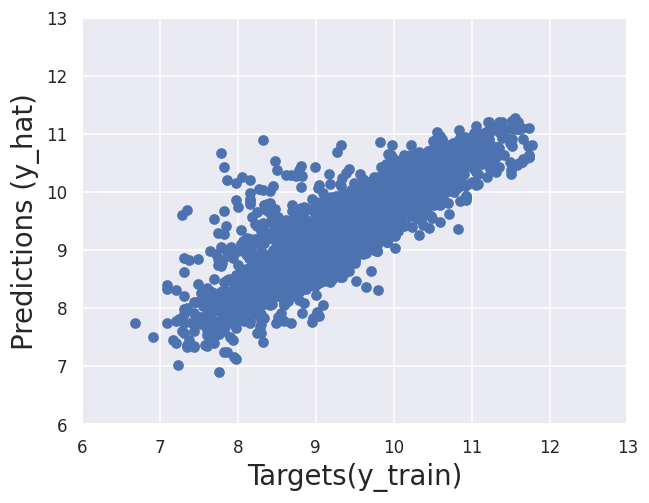

In [ ]:
plt.scatter(y_train, y_hat)
plt.xlabel('Targets(y_train)',size=18)
plt.ylabel('Predictions (y_hat)',size=18)
plt.xlim(6,13)
plt.ylim(6,13)
plt.show()

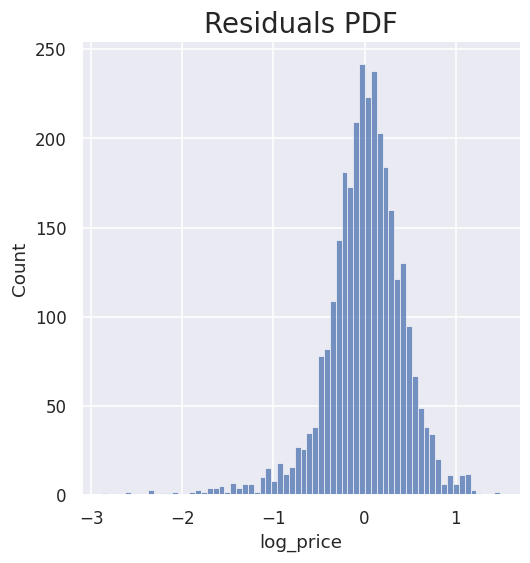

In [ ]:
sns.displot(y_train - y_hat)
plt.title('Residuals PDF',size=18)

A negative residual means the predicted log price is higher than the observed log price. The left tail shows some sizable overestimates.

### Training R² and coefficients

The next score measures fit on the training log prices.

In [ ]:
reg.score(x_train,y_train)

0.744996578792662

In [ ]:
reg_summary = pd.DataFrame(inputs.columns.values, columns=['Features'])
reg_summary['Weights'] = reg.coef_
reg_summary

,Features,Weights
0,Mileage,-0.443648
1,EngineV,0.209676
2,Brand_BMW,0.014156
3,Brand_Mercedes-Benz,0.012842
4,Brand_Mitsubishi,-0.140671
5,Brand_Renault,-0.182710
6,Brand_Toyota,-0.060980
7,Brand_Volkswagen,-0.089768
8,Body_hatch,-0.143662
9,Body_other,-0.100527


### Evaluate on the test set

On the scatter plot, the dashed line marks a perfect prediction. I convert both the predictions and targets back to dollars before calculating errors.

In [ ]:
y_hat_test = reg.predict(x_test)

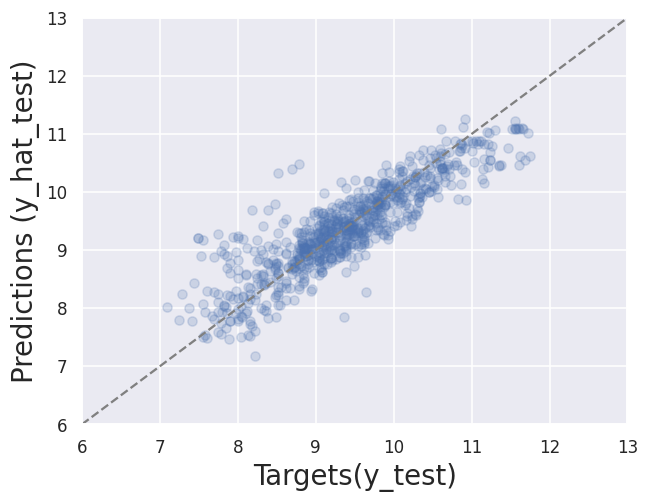

In [ ]:
plt.scatter(y_test, y_hat_test, alpha=0.2)
plt.plot([6, 13], [6, 13], linestyle='--', color='gray')
plt.xlabel('Targets(y_test)',size=18)
plt.ylabel('Predictions (y_hat_test)',size=18)
plt.xlim(6,13)
plt.ylim(6,13)
plt.show()

In [ ]:
df_pf = pd.DataFrame(np.exp(y_hat_test), columns=['Prediction'])
df_pf.head()

,Prediction
0,10685.501696
1,3499.255242
2,7553.285218
3,7463.963017
4,11353.490075


In [ ]:
y_test = y_test.reset_index(drop=True)
y_test.head()

0    7.740664
1    7.937375
2    7.824046
3    8.764053
4    9.121509
Name: log_price, dtype: float64

In [ ]:
df_pf['Target']=np.exp(y_test)

In [ ]:
df_pf['Residual']=df_pf['Target']- df_pf['Prediction']

In [ ]:
df_pf['Difference%'] =np.absolute (df_pf['Residual']/df_pf['Target']*100)

In [ ]:
df_pf.describe()

,Prediction,Target,Residual,Difference%
count,774.000000,774.000000,774.000000,774.000000
mean,15946.760167,18165.817106,2219.056939,36.256693
std,13133.197604,19967.858908,10871.218143,55.066507
min,1320.562768,1200.000000,-29456.498331,0.062794
25%,7413.644234,6900.000000,-2044.191251,12.108022
50%,11568.168859,11600.000000,142.518577,23.467728
75%,20162.408805,20500.000000,3147.343497,39.563570
max,77403.055224,126000.000000,85106.162329,512.688080


## 5. Test the model name and the log transformation

The test plot shows sizable misses on some cars. A brand label alone groups together cars that may sell at very different prices. I add `Model` back to see if it helps, then test whether the log transformation still pays off.

I recover the original model names using the row indices retained through cleaning. All three fits use the same 3,093 training rows and 774 test rows. The encoders and scaler learn from the training rows. The cleaning thresholds were calculated before the split, so the results describe the filtered dataset from this exercise.

In [ ]:
from scipy.sparse import csr_matrix, hstack
from sklearn.preprocessing import OneHotEncoder

comparison_data = data_4.copy()
comparison_data['Model'] = raw_data.loc[data_4.index, 'Model']
comparison_data = comparison_data.reset_index(drop=True)

train_cars, test_cars = train_test_split(
    comparison_data, test_size=0.2, random_state=365
)

numeric_columns = ['Mileage', 'EngineV']
category_columns = ['Brand', 'Body', 'Engine Type', 'Registration']

category_encoder = OneHotEncoder(
    drop='first', handle_unknown='ignore', sparse_output=False
)
train_base = np.column_stack([
    train_cars[numeric_columns],
    category_encoder.fit_transform(train_cars[category_columns])
])
test_base = np.column_stack([
    test_cars[numeric_columns],
    category_encoder.transform(test_cars[category_columns])
])

comparison_scaler = StandardScaler()
train_base = comparison_scaler.fit_transform(train_base)
test_base = comparison_scaler.transform(test_base)

model_encoder = OneHotEncoder(handle_unknown='ignore')
train_model = hstack([
    csr_matrix(train_base), model_encoder.fit_transform(train_cars[['Model']])
], format='csr')
test_model = hstack([
    csr_matrix(test_base), model_encoder.transform(test_cars[['Model']])
], format='csr')

In [ ]:
train_log_price = np.log(train_cars['Price'])
actual_prices = test_cars['Price'].to_numpy()

baseline = LinearRegression().fit(train_base, train_log_price)
log_with_model = LinearRegression(tol=1e-11).fit(train_model, train_log_price)
raw_with_model = LinearRegression(tol=1e-11).fit(train_model, train_cars['Price'])

predictions = pd.DataFrame({
    'Log price without Model': np.exp(baseline.predict(test_base)),
    'Log price with Model': np.exp(log_with_model.predict(test_model)),
    'Raw price with Model': raw_with_model.predict(test_model)
})

absolute_errors = predictions.sub(actual_prices, axis='index').abs()
percentage_errors = absolute_errors.div(actual_prices, axis='index') * 100

comparison = pd.DataFrame({
    'Mean absolute error ($)': absolute_errors.mean(),
    'Median absolute percentage error (%)': percentage_errors.median(),
    'Predictions within 25% (%)': percentage_errors.le(25).mean() * 100,
    'Negative predictions': predictions.lt(0).sum()
})
comparison.round(2)

,Mean absolute error ($),Median absolute percentage error (%),Predictions within 25% (%),Negative predictions
Log price without Model,5563.98,23.47,52.84,0
Log price with Model,4295.59,18.83,62.27,0
Raw price with Model,6050.49,28.71,45.48,54


In [ ]:
price_bands = pd.cut(
    actual_prices,
    bins=[0, 7000, 20000, np.inf],
    labels=['Under $7,000', '$7,000 to under $20,000', '$20,000 and up'],
    right=False
)

price_band_errors = absolute_errors.groupby(price_bands, observed=True).mean()
price_band_errors.index.name = 'Actual price range'
price_band_errors.insert(0, 'Test cars', pd.Series(price_bands).value_counts().reindex(price_band_errors.index))
price_band_errors.round(2)

,Test cars,Log price without Model,Log price with Model,Raw price with Model
Actual price range,,,,
"Under $7,000",203,2480.50,2175.61,5406.29
"$7,000 to under $20,000",373,2948.90,2441.81,4145.61
"$20,000 and up",198,13651.69,9961.34,10299.47


In [ ]:
unseen_model = ~test_cars['Model'].isin(train_cars['Model']).to_numpy()

print(f'Test cars with a model name absent from training: {unseen_model.sum()}')
absolute_errors.loc[
    unseen_model, ['Log price without Model', 'Log price with Model']
].mean().round(2)

Test cars with a model name absent from training: 24


Log price without Model    6091.73
Log price with Model       7309.87
dtype: float64

### What changed

- Adding `Model` lowered mean absolute error from \$5,564 to \$4,296, a **23% reduction**. It helped in all three price ranges, with the largest dollar improvement for cars priced at \$20,000 and up.
- For the 24 test cars whose model names did not appear in the training data, the average absolute error rose from \$6,092 to \$7,310 after adding `Model`.
- Training directly on dollar prices increased mean absolute error to \$6,050 and produced **54 negative price estimates**. The model trained on log prices with `Model` performed best on this test split.